In [ ]:
from pathlib import Path
from PIL import Image
from collections import Counter
import matplotlib.pyplot as plt

In [ ]:
dataset_path = Path("20_class_dataset (1)")

train_path = dataset_path / "Train"
validation_path = dataset_path / "Validation"

print("Train folder exists:", train_path.exists())
print("Validation folder exists:", validation_path.exists())

Train folder exists: True
Validation folder exists: True


In [ ]:
def get_image_sizes(folder):
    sizes = Counter()
    total = 0

    for path in folder.rglob("*"):
        if path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
            try:
                with Image.open(path) as img:
                    sizes[img.size] += 1
                    total += 1
            except:
                pass

    return total, sizes


train_total, train_sizes = get_image_sizes(train_path)
validation_total, validation_sizes = get_image_sizes(validation_path)

print("Train images:", train_total)
print("Train image sizes:", train_sizes)

print("Validation images:", validation_total)
print("Validation image sizes:", validation_sizes)

Train images: 11663
Train image sizes: Counter({(300, 300): 4624, (256, 256): 1716, (493, 1040): 585, (780, 1040): 263, (1040, 493): 140, (585, 1040): 136, (6000, 4000): 106, (224, 224): 70, (758, 1600): 58, (380, 250): 32, (250, 380): 32, (694, 694): 32, (750, 1000): 27, (720, 540): 25, (259, 194): 23, (540, 720): 23, (1024, 768): 22, (300, 225): 22, (225, 300): 21, (3081, 897): 21, (622, 1280): 21, (768, 1024): 19, (275, 183): 16, (295, 221): 16, (194, 259): 13, (1600, 758): 13, (500, 375): 12, (3264, 1836): 12, (900, 1600): 12, (493, 983): 12, (499, 332): 12, (221, 295): 12, (183, 275): 12, (493, 986): 11, (1040, 585): 11, (288, 216): 11, (521, 348): 11, (600, 400): 10, (612, 816): 10, (284, 426): 10, (331, 497): 10, (381, 571): 10, (1024, 683): 9, (539, 501): 9, (493, 988): 9, (216, 288): 9, (219, 292): 9, (217, 289): 9, (426, 284): 9, (497, 331): 9, (493, 329): 9, (571, 381): 9, (538, 359): 9, (222, 296): 9, (359, 538): 9, (600, 380): 9, (500, 667): 9, (486, 486): 8, (471, 561): 8

In [ ]:
from pathlib import Path
from PIL import Image
from collections import Counter

dataset_path = Path("20_class_dataset (1)")
train_path = dataset_path / "Train"
validation_path = dataset_path / "Validation"

print("Dataset found:", dataset_path.exists())
print("Train found:", train_path.exists())
print("Validation found:", validation_path.exists())

Dataset found: True
Train found: True
Validation found: True


In [ ]:
def get_image_sizes(folder):
    sizes = Counter()
    total = 0
    errors = []

    for path in folder.rglob("*"):
        if path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
            try:
                with Image.open(path) as img:
                    sizes[img.size] += 1
                    total += 1
            except Exception as e:
                errors.append((str(path), str(e)))

    return total, sizes, errors


train_total, train_sizes, train_errors = get_image_sizes(train_path)
val_total, val_sizes, val_errors = get_image_sizes(validation_path)

print("Train images:", train_total)
print("Train dimensions:", train_sizes)

print("\nValidation images:", val_total)
print("Validation dimensions:", val_sizes)

print("\nErrors:", len(train_errors) + len(val_errors))

Train images: 11663
Train dimensions: Counter({(300, 300): 4624, (256, 256): 1716, (493, 1040): 585, (780, 1040): 263, (1040, 493): 140, (585, 1040): 136, (6000, 4000): 106, (224, 224): 70, (758, 1600): 58, (380, 250): 32, (250, 380): 32, (694, 694): 32, (750, 1000): 27, (720, 540): 25, (259, 194): 23, (540, 720): 23, (1024, 768): 22, (300, 225): 22, (225, 300): 21, (3081, 897): 21, (622, 1280): 21, (768, 1024): 19, (275, 183): 16, (295, 221): 16, (194, 259): 13, (1600, 758): 13, (500, 375): 12, (3264, 1836): 12, (900, 1600): 12, (493, 983): 12, (499, 332): 12, (221, 295): 12, (183, 275): 12, (493, 986): 11, (1040, 585): 11, (288, 216): 11, (521, 348): 11, (600, 400): 10, (612, 816): 10, (284, 426): 10, (331, 497): 10, (381, 571): 10, (1024, 683): 9, (539, 501): 9, (493, 988): 9, (216, 288): 9, (219, 292): 9, (217, 289): 9, (426, 284): 9, (497, 331): 9, (493, 329): 9, (571, 381): 9, (538, 359): 9, (222, 296): 9, (359, 538): 9, (600, 380): 9, (500, 667): 9, (486, 486): 8, (471, 561): 8,

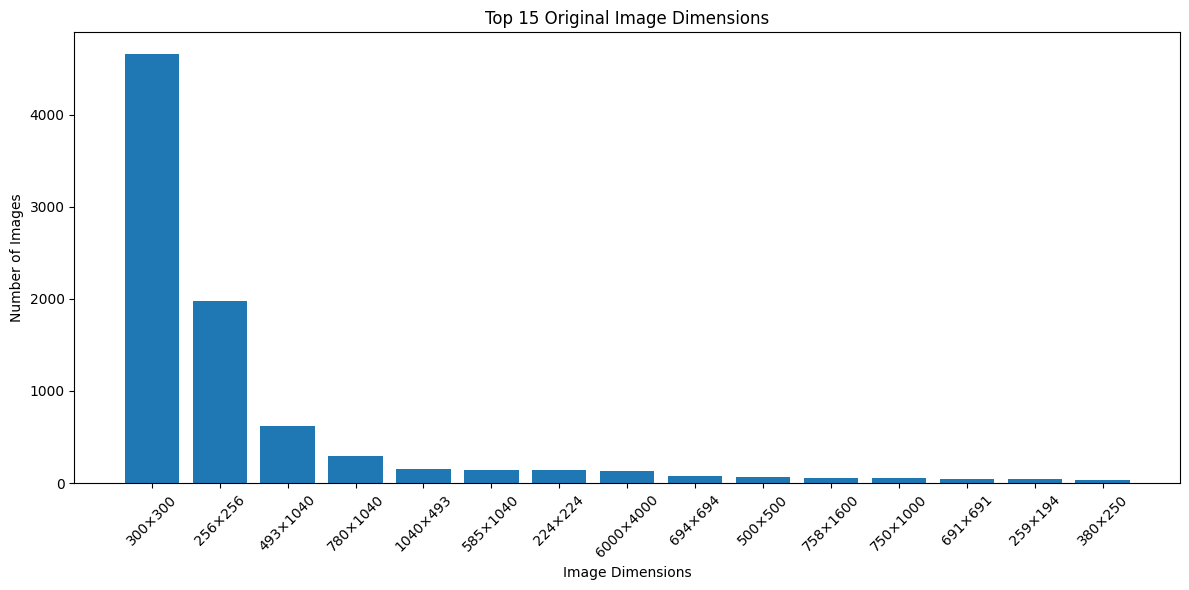

In [ ]:
import matplotlib.pyplot as plt

all_sizes = train_sizes + val_sizes

top_sizes = all_sizes.most_common(15)

labels = [f"{size[0]}×{size[1]}" for size, count in top_sizes]
counts = [count for size, count in top_sizes]

plt.figure(figsize=(12, 6))
plt.bar(labels, counts)

plt.title("Top 15 Original Image Dimensions")
plt.xlabel("Image Dimensions")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
from PIL import Image

dataset_path = Path("20_class_dataset (1)")
output_path = Path("Resized_Dataset")

TARGET_SIZE = (224, 224)
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def resize_split(split_name):
    source_split = dataset_path / split_name
    output_split = output_path / split_name

    for class_folder in source_split.iterdir():
        if not class_folder.is_dir():
            continue

        output_class = output_split / class_folder.name
        output_class.mkdir(parents=True, exist_ok=True)

        for image_path in class_folder.iterdir():
            if image_path.suffix.lower() not in extensions:
                continue

            try:
                with Image.open(image_path) as image:
                    resized = image.resize(
                        TARGET_SIZE,
                        Image.Resampling.LANCZOS
                    )

                    resized.save(output_class / image_path.name)

            except Exception as e:
                print("Error:", image_path, e)


resize_split("Train")
resize_split("Validation")

print("Resizing completed.")

Error: 20_class_dataset (1)\Train\Becterial Blight in Rice\BACTERAILBLIGHT3_076.jpg cannot write mode RGBA as JPEG
Error: 20_class_dataset (1)\Train\Becterial Blight in Rice\BACTERAILBLIGHT3_078.jpg cannot write mode RGBA as JPEG
Error: 20_class_dataset (1)\Train\Becterial Blight in Rice\BACTERAILBLIGHT3_080.jpg cannot write mode RGBA as JPEG
Error: 20_class_dataset (1)\Train\Becterial Blight in Rice\BACTERAILBLIGHT3_082.jpg cannot write mode RGBA as JPEG
Error: 20_class_dataset (1)\Train\Becterial Blight in Rice\BACTERAILBLIGHT3_092.jpg cannot write mode RGBA as JPEG
Error: 20_class_dataset (1)\Train\Becterial Blight in Rice\BACTERAILBLIGHT3_094.jpg cannot write mode RGBA as JPEG
Error: 20_class_dataset (1)\Train\Becterial Blight in Rice\BACTERAILBLIGHT3_096.jpg cannot write mode RGBA as JPEG
Error: 20_class_dataset (1)\Train\Becterial Blight in Rice\BACTERAILBLIGHT3_098.jpg cannot write mode RGBA as JPEG
Error: 20_class_dataset (1)\Train\Becterial Blight in Rice\BACTERAILBLIGHT3_100.

In [ ]:
import shutil
from pathlib import Path

output_path = Path("Resized_Dataset")

if output_path.exists():
    shutil.rmtree(output_path)

print("Old incomplete resized dataset removed.")

Old incomplete resized dataset removed.


In [ ]:
from pathlib import Path
from PIL import Image

dataset_path = Path("20_class_dataset (1)")
output_path = Path("Resized_Dataset")

TARGET_SIZE = (224, 224)
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def resize_split(split_name):
    source_split = dataset_path / split_name
    output_split = output_path / split_name

    for class_folder in source_split.iterdir():
        if not class_folder.is_dir():
            continue

        output_class = output_split / class_folder.name
        output_class.mkdir(parents=True, exist_ok=True)

        for image_path in class_folder.iterdir():
            if image_path.suffix.lower() not in extensions:
                continue

            try:
                with Image.open(image_path) as image:

                    # Convert RGBA/RGB/etc. to RGB
                    if image.mode != "RGB":
                        image = image.convert("RGB")

                    # Resize to 224 × 224
                    resized = image.resize(
                        TARGET_SIZE,
                        Image.Resampling.LANCZOS
                    )

                    resized.save(output_class / image_path.name)

            except Exception as e:
                print("Error:", image_path, e)


resize_split("Train")
resize_split("Validation")

print("Resizing completed.")

C:\Users\HP\anaconda3\Lib\site-packages\PIL\Image.py:1137: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Resizing completed.


In [ ]:
from collections import Counter
from pathlib import Path
from PIL import Image

resized_path = Path("Resized_Dataset")

sizes = Counter()
count = 0
errors = []

for path in resized_path.rglob("*"):
    if path.suffix.lower() in extensions:
        try:
            with Image.open(path) as img:
                sizes[img.size] += 1
                count += 1
        except Exception as e:
            errors.append((str(path), str(e)))

print("Total resized images:", count)
print("Image sizes:", sizes)
print("Errors:", len(errors))

Total resized images: 13675
Image sizes: Counter({(224, 224): 13675})
Errors: 0


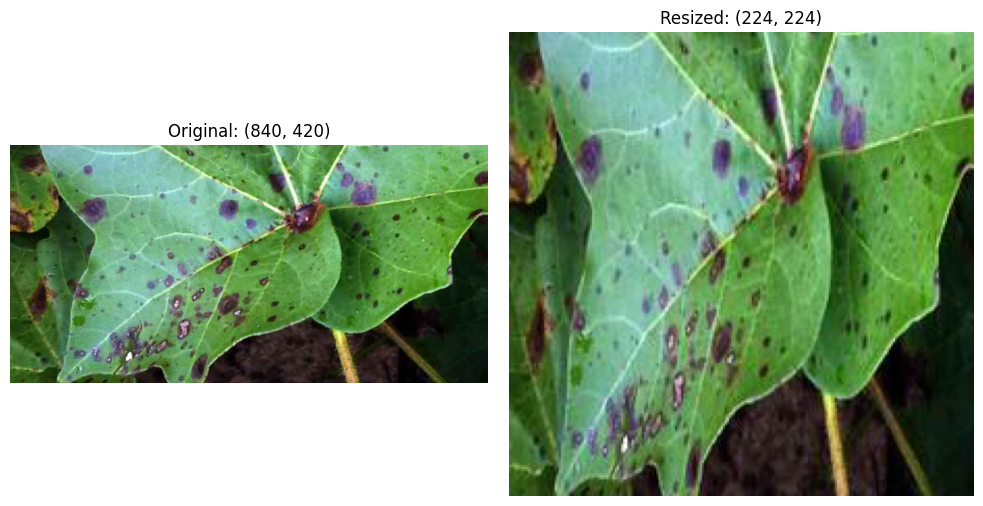

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Find one image from the original dataset
original_path = next(
    path for path in (dataset_path / "Train").rglob("*")
    if path.suffix.lower() in extensions
)

# Find the corresponding resized image
relative_path = original_path.relative_to(dataset_path / "Train")
resized_image_path = output_path / "Train" / relative_path

# Open both images
original = Image.open(original_path)
resized = Image.open(resized_image_path)

# Display original and resized
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title(f"Original: {original.size}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized)
plt.title(f"Resized: {resized.size}")
plt.axis("off")

plt.tight_layout()
plt.show()

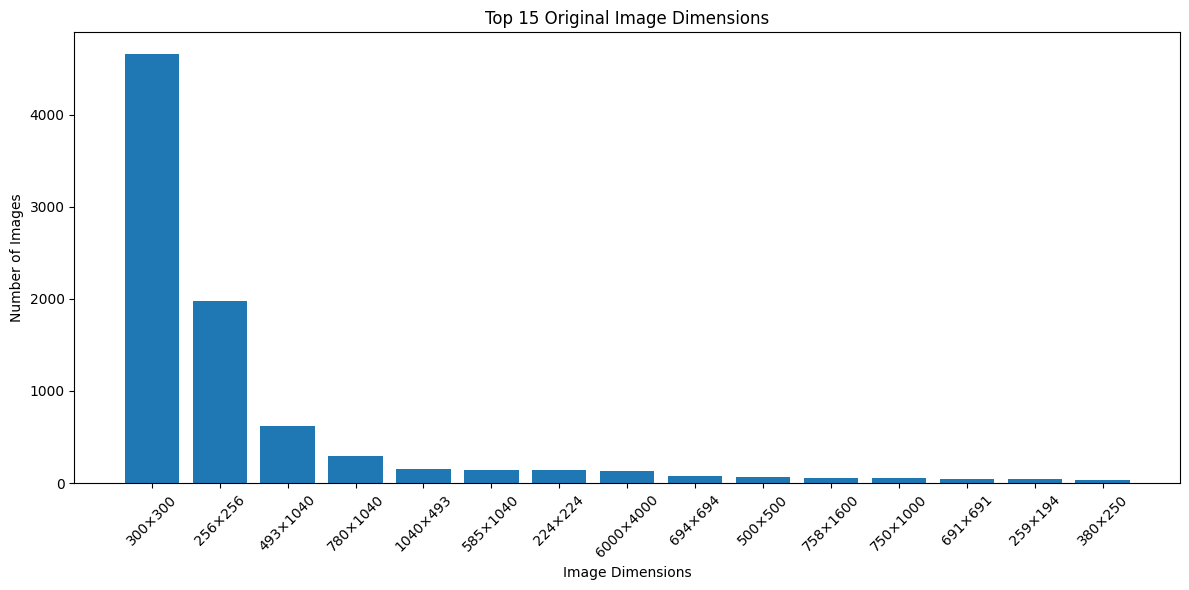

Graph saved as Original_Image_Dimensions.png


In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(labels, counts)

plt.title("Top 15 Original Image Dimensions")
plt.xlabel("Image Dimensions")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("Original_Image_Dimensions.png", dpi=300)
plt.show()

print("Graph saved as Original_Image_Dimensions.png")

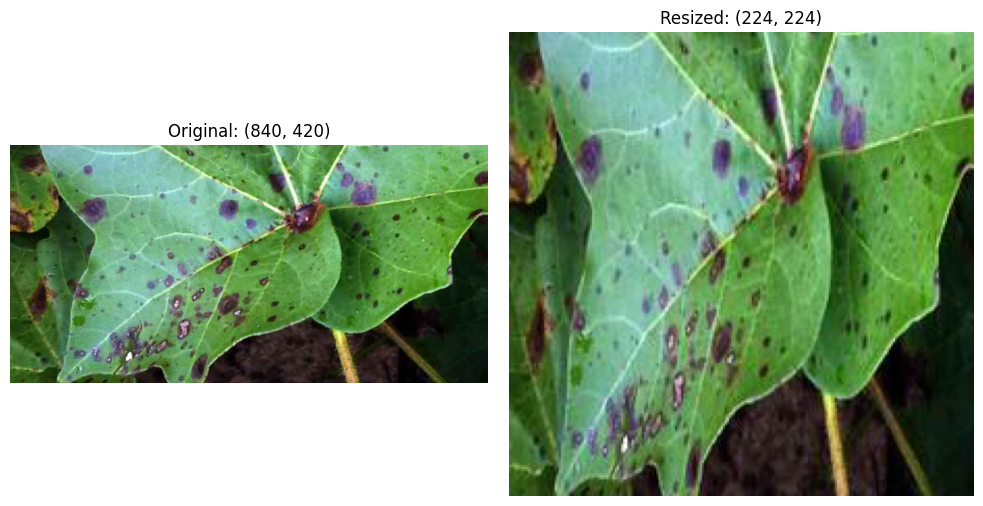

Before/after image saved as Original_vs_Resized.png


In [ ]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title(f"Original: {original.size}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized)
plt.title(f"Resized: {resized.size}")
plt.axis("off")

plt.tight_layout()
plt.savefig("Original_vs_Resized.png", dpi=300)
plt.show()

print("Before/after image saved as Original_vs_Resized.png")

In [ ]:
from collections import Counter
from pathlib import Path

resized_path = Path("Resized_Dataset")

for split in ["Train", "Validation"]:
    print("\n", split)

    counts = {}

    split_path = resized_path / split

    for class_folder in split_path.iterdir():
        if class_folder.is_dir():
            count = sum(
                1 for file in class_folder.iterdir()
                if file.suffix.lower() in extensions
            )
            counts[class_folder.name] = count

    for class_name, count in sorted(counts.items()):
        print(class_name, ":", count)

    print("Total:", sum(counts.values()))


 Train
Becterial Blight in Rice : 1584
Brownspot : 1640
Gray_Leaf_Spot : 574
Healthy Maize : 1162
Healthy Wheat : 180
Healthy cotton : 426
Mosaic sugarcane : 462
RedRot sugarcane : 592
Rice Blast : 1440
Sugarcane Healthy : 522
Tungro : 1308
Wheat Stem fly : 172
Wheat black rust : 161
Wheat powdery mildew : 169
Wilt : 419
bacterial_blight in Cotton : 489
cotton mealy bug : 92
maize fall armyworm : 107
maize stem borer : 95
red cotton bug : 69
Total: 11663

 Validation
Becterial Blight in Rice : 22
Brownspot : 9
Gray_Leaf_Spot : 20
Healthy Maize : 275
Healthy Wheat : 33
Healthy cotton : 176
Mosaic sugarcane : 66
RedRot sugarcane : 153
Rice Blast : 44
Sugarcane Healthy : 94
Tungro : 9
Wheat Stem fly : 62
Wheat black rust : 70
Wheat powdery mildew : 42
Wilt : 419
bacterial_blight in Cotton : 284
cotton mealy bug : 58
maize fall armyworm : 75
maize stem borer : 57
red cotton bug : 44
Total: 2012


In [ ]:
summary = """Member 01 - Image Resizing

Preprocessing Technique:
Image Resizing

Target Image Size:
224 × 224 pixels

Original Dataset:
20-class crop disease dataset

Original Image Count:
Train: 11,663
Validation: 2,012
Total: 13,675

Resizing Method:
Pillow Image.Resampling.LANCZOS

Final Image Size:
224 × 224 for all images

Verification:
All resized images were checked and confirmed as 224 × 224.
No image processing errors were found during verification.

EDA Outputs:
1. Original_Image_Dimensions.png
2. Original_vs_Resized.png
"""

with open("Member_01_Resizing_Summary.txt", "w") as file:
    file.write(summary)

print("Summary file created successfully.")

Summary file created successfully.
